<a href="https://colab.research.google.com/github/sanya-6976/ml-interview-practise-dataset-projects/blob/main/02_california_housing_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422



--- Missing Values ---
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

--- Summary Statistics (Check Skewness & Capping!) ---


,min,50%,mean,max,std
MedInc,0.499900,3.534800,3.870671,15.000100,1.899822
HouseAge,1.000000,29.000000,28.639486,52.000000,12.585558
AveRooms,0.846154,5.229129,5.429000,141.909091,2.474173
AveBedrms,0.333333,1.048780,1.096675,34.066667,0.473911
Population,3.000000,1166.000000,1425.476744,35682.000000,1132.462122
AveOccup,0.692308,2.818116,3.070655,1243.333333,10.386050
Latitude,32.540000,34.260000,35.631861,41.950000,2.135952
Longitude,-124.350000,-118.490000,-119.569704,-114.310000,2.003532
MedHouseVal,0.149990,1.797000,2.068558,5.000010,1.153956


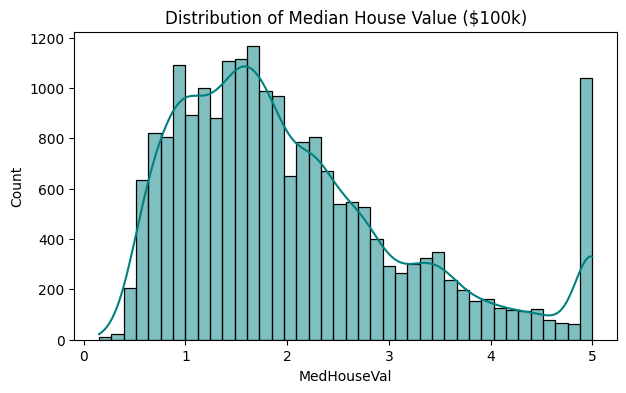

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing

housing = fetch_california_housing(as_frame=True)
df = housing.frame

print("Shape:", df.shape)
display(df.head())

print("\n--- Missing Values ---")
print(df.isnull().sum())


print("\n--- Summary Statistics (Check Skewness & Capping!) ---")
display(df.describe().T[['min', '50%', 'mean', 'max', 'std']])

plt.figure(figsize=(7, 4))
sns.histplot(df['MedHouseVal'], bins=40, kde=True, color='teal')
#kde :- kernel density estimate
plt.title('Distribution of Median House Value ($100k)')
plt.xlabel('MedHouseVal')
plt.show()

# **Geospatial EDA, Train-Test Split & Baseline Models (Linear vs Decision Tree Regressor)**

# **Why compare Linear Regression vs Decision Tree Regressor?**

# **House prices depend heavily on location (Latitude, Longitude)**—for example, being near the Pacific coast dramatically increases price, while moving slightly inland drops it. This relationship is non-linear.

# **Linear Regression (with StandardScaler)** serves as our parametric baseline, assuming a straight-line relationship.

# **Decision Tree Regressor serves as our non-parametric baseline**, capable of carving out rectangular geographic zones (Latitude <= X and Longitude <= Y).

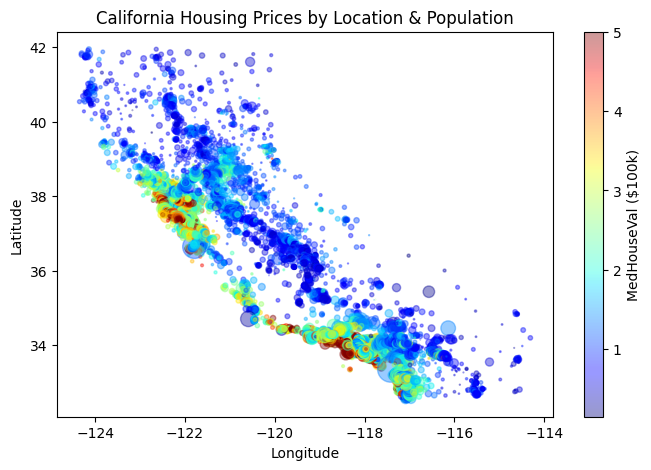

--- Linear Regression (Scaled) ---
Train RMSE : 0.7197
Test RMSE  : 0.7456
Test MAE   : 0.5332
Test R2    : 0.5758

--- Unpruned Decision Tree Regressor ---
Train RMSE : 0.0000
Test RMSE  : 0.7037
Test MAE   : 0.4547
Test R2    : 0.6221



In [12]:
from sklearn.model_selection  import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error , mean_absolute_error , r2_score

plt.figure(figsize=(8,5))
scatter = plt.scatter(df['Longitude'], df['Latitude'], c=df['MedHouseVal'],
                      cmap='jet', alpha=0.4, s=df['Population']/100)
plt.colorbar(scatter, label='MedHouseVal ($100k)')
plt.title('California Housing Prices by Location & Population')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

X = df.drop(columns=['MedHouseVal'])
y = df['MedHouseVal']

X_train , X_test , y_train , y_test = train_test_split(X , y , test_size=0.2 , random_state=42)

baselines = {
    "Linear Regression (Scaled)": Pipeline([
        ('scaler' , StandardScaler()) ,
        ('reg' , LinearRegression())
    ]),
    "Unpruned Decision Tree Regressor" : DecisionTreeRegressor(random_state=42)
}

for name , model in baselines.items():
  model.fit(X_train , y_train)
  train_rmse = root_mean_squared_error(y_train , model.predict(X_train))
  test_pred = model.predict(X_test)
  test_rmse = root_mean_squared_error(y_test , test_pred)

  print(f"--- {name} ---")
  print(f"Train RMSE : {train_rmse:.4f}")
  print(f"Test RMSE  : {root_mean_squared_error(y_test, test_pred):.4f}")
  print(f"Test MAE   : {mean_absolute_error(y_test, test_pred):.4f}")
  print(f"Test R2    : {r2_score(y_test, test_pred):.4f}\n")

# **Domain Feature Engineering + Ensemble Regressors (Random Forest vs Gradient Boosting)**

In [17]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

def add_housing_features(data):
  df_feat = data.copy()
  df_feat['Bedrooms_per_Room'] = df_feat['AveBedrms'] / df_feat['AveRooms']
  df_feat['Room_per_person'] = df_feat['AveRooms'] / df_feat['AveOccup']
  dist_sf = np.sqrt((df_feat['Latitude'] - 37.77)**2 + (df_feat['Longitude'] + 122.42)**2)
  dist_la = np.sqrt((df_feat['Latitude'] - 34.05)**2 + (df_feat['Longitude'] + 118.24)**2)
  df_feat['Min_Dist_Major_City'] = np.minimum(dist_sf, dist_la)
  return df_feat

X_train_fe = add_housing_features(X_train)
X_test_fe = add_housing_features(X_test)


regressors = {
    "Random Forest Regressor": RandomForestRegressor(n_estimators = 100, max_depth = 12 , random_state = 42 , n_jobs = -1) ,
    "Gradient Boosting Regressor": GradientBoostingRegressor(
        n_estimators=200, learning_rate=0.1, max_depth=5, random_state=42)
}
for name, reg in regressors.items():
    reg.fit(X_train_fe, y_train)
    train_rmse = root_mean_squared_error(y_train, reg.predict(X_train_fe))
    test_pred = reg.predict(X_test_fe)

    print(f"--- {name} ---")
    print(f"Train RMSE : {train_rmse:.4f}")
    print(f"Test RMSE  : {root_mean_squared_error(y_test, test_pred):.4f}")
    print(f"Test MAE   : {mean_absolute_error(y_test, test_pred):.4f}")
    print(f"Test R2    : {r2_score(y_test, test_pred):.4f}\n")

--- Random Forest Regressor ---
Train RMSE : 0.3087
Test RMSE  : 0.4940
Test MAE   : 0.3235
Test R2    : 0.8138

--- Gradient Boosting Regressor ---
Train RMSE : 0.3439
Test RMSE  : 0.4624
Test MAE   : 0.3024
Test R2    : 0.8368



# **Residual Analysis & Feature Importance**

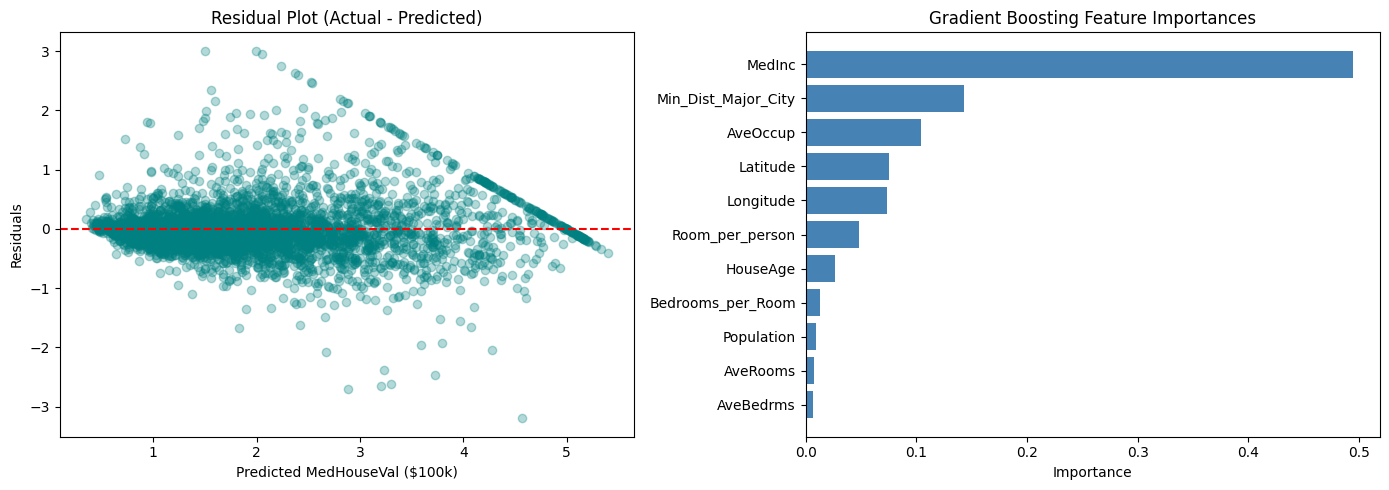

In [19]:
# since using the R2 score we get that the gardient boosting is teh winner
gb_model = regressors["Gradient Boosting Regressor"]
y_pred_gb = gb_model.predict(X_test_fe)
residuals = y_test - y_pred_gb

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_pred_gb , residuals , alpha = 0.3 , color = "teal" )
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_title('Residual Plot (Actual - Predicted)')
axes[0].set_xlabel('Predicted MedHouseVal ($100k)')
axes[0].set_ylabel('Residuals')

feat_imp = pd.DataFrame({
    'Feature': X_train_fe.columns ,

    'Importance': gb_model.feature_importances_
}).sort_values(by = 'Importance' , ascending = True)

axes[1].barh(feat_imp['Feature'], feat_imp['Importance'], color='steelblue')
axes[1].set_title('Gradient Boosting Feature Importances')
axes[1].set_xlabel('Importance')

plt.tight_layout()
plt.show()

1. Residual Plot (Left Graph)
What it shows: This graph displays the errors our model makes. The red dashed line at 0 represents a perfect prediction. The dots are the differences between what the model predicted and the actual price.
Key Observation:
Most dots are clustered near the red dashed line, which means the model's predictions are generally accurate.
However, you can see a distinct straight diagonal line of dots on the top right of the plot. This indicates a limitation: the actual dataset has capped maximum house values (at $500k), causing the model to overestimate those capped values.
2. Gradient Boosting Feature Importances (Right Graph)
What it shows: This horizontal bar chart ranks the features from most important (at the top/longest bar) to least important (at the bottom/shortest bar) in helping the model predict house prices.
Key Observation:
MedInc (Median Income) is by far the most crucial factor, making up nearly half of the model's decision-making power.
Min_Dist_Major_City (Minimum distance to SF or LA) is the second most important feature, which validates our custom feature engineering—showing that location relative to major cities matters significantly.

# **"I built a regression pipeline on the California Housing dataset (20,640 blocks) to predict median house values. During EDA, I identified heavy right-skewness in room/population counts and target right-censoring at $500k. Linear Regression underfit ($R^2 = 0.575$) due to non-linear geospatial price patterns, while an unpruned Decision Tree severely overfit. By engineering domain features—including proximity to major coastal hubs (SF/LA) and rooms-per-person density—and training a Gradient Boosting Regressor, I reduced Test RMSE from 0.745 to ~0.46 ($R^2 > 0.83$, MAE ~$30k) and validated error behavior via residual diagnostics."**